In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

scores = pd.read_csv('data/2010-2026_scores.csv')
plays = pd.concat([
    pd.read_csv('data/2010_plays.csv'),
    pd.read_csv('data/2011_plays.csv'),
    pd.read_csv('data/2012_plays.csv'),
    pd.read_csv('data/2013_plays.csv'),
    pd.read_csv('data/2014_plays.csv'),
    pd.read_csv('data/2015_plays.csv'),
    pd.read_csv('data/2016_plays.csv'),
    pd.read_csv('data/2017_plays.csv'),
    pd.read_csv('data/2018_plays.csv'),
    pd.read_csv('data/2019_plays.csv'),
    pd.read_csv('data/2020_plays.csv'),
    pd.read_csv('data/2021_plays.csv'),
    pd.read_csv('data/2022_plays.csv'),
    pd.read_csv('data/2023_plays.csv'),
    pd.read_csv('data/2024_plays.csv'),
    pd.read_csv('data/2025_plays.csv'),
    pd.read_csv('data/2026_plays.csv')
], ignore_index=True)

scores = scores[scores['GameStatus'] == 'FINAL']
scores['AwayScore'] = scores['AwayScore'].astype(int)
scores['HomeScore'] = scores['HomeScore'].astype(int)
quarter_map = {'1st Quarter': 1, '2nd Quarter': 2, '3rd Quarter': 3, '4th Quarter': 4, 'Overtime': 5, '2nd Overtime': 6}
plays['Quarter'] = plays['Quarter'].map(quarter_map)
print(scores.dtypes)

nfl = plays.merge(scores[['Season', 'Week', 'AwayTeam', 'HomeTeam', 'GameDate', 'AwayScore', 'HomeScore']], on=['Season', 'Week', 'AwayTeam', 'HomeTeam'])
nfl.head()

Season        int64
Week            str
GameStatus      str
GameSlot        str
GameDate        str
AwayTeam        str
AwayScore     int64
HomeTeam        str
HomeScore     int64
dtype: object


,Season,Week,GameSlot,Date,AwayTeam,HomeTeam,Quarter,DriveNumber,TeamWithPossession,IsScoringDrive,PlayNumberInDrive,IsScoringPlay,PlayOutcome,PlayStart,PlayTimeFormation,PlayDescription,GameDate,AwayScore,HomeScore
0,2010,HALL OF FAME,Sunday,August 8th,DAL,CIN,1,1,Dallas Cowboys,1,1,0,Kickoff from CIN 30,NaN,Kickoff,— D.Rayner kicks 73 yards from CIN 30 to DAL -...,August 8th,16,7
1,2010,HALL OF FAME,Sunday,August 8th,DAL,CIN,1,1,Dallas Cowboys,1,2,0,Pass Incomplete,1st & 10 at DAL 35,15:00 1st,— T.Romo pass incomplete short right to M.Austin.,August 8th,16,7
2,2010,HALL OF FAME,Sunday,August 8th,DAL,CIN,1,1,Dallas Cowboys,1,3,0,16 Yard Pass,2nd & 10 at DAL 35,15:00 1st Shotgun,— T.Romo pass short left to M.Austin to CIN 49...,August 8th,16,7
3,2010,HALL OF FAME,Sunday,August 8th,DAL,CIN,1,1,Dallas Cowboys,1,4,0,5 Yard Run,1st & 10 at CIN 49,14:26 1st,— M.Barber left guard to CIN 44 for 5 yards (K...,August 8th,16,7
4,2010,HALL OF FAME,Sunday,August 8th,DAL,CIN,1,1,Dallas Cowboys,1,5,0,4 Yard Run,2nd & 5 at CIN 44,13:52 1st,— F.Jones left guard to CIN 40 for 4 yards (R....,August 8th,16,7


## Hypothesis Test: Home-Field Advantage (By: Hriday Khadka)

Do home teams score more points than away teams?

- H0 (Null Hypothesis): There is no difference in the amount of points scored by home teams and away teams (mean of HomeScore − AwayScore = 0).
- H1 (Alternative Hypothesis): Home teams score more points than away teams (mean of HomeScore − AwayScore > 0).
- Significance level: α = 0.05

In [54]:
scores['Margin'] = scores['HomeScore'] - scores['AwayScore']

print("Number of games:", len(scores))
print("Mean margin:", scores['Margin'].mean())
print("Median margin:", scores['Margin'].median())
print("Std of margin:", scores['Margin'].std())
print("Home win rate:", (scores['Margin'] > 0).mean())

Number of games: 5409
Mean margin: 1.8631909779996303
Median margin: 2.0
Std of margin: 14.205622020535841
Home win rate: 0.5500092438528379


In [55]:
from scipy import stats

t_stat, p_value = stats.ttest_rel(scores['HomeScore'], scores['AwayScore'], alternative='greater')

print("t-statistic:", t_stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("Reject the null hypothesis: home teams score significantly more.")
else:
    print("Fail to reject the null hypothesis.")

t-statistic: 9.646185479567448
p-value: 3.821529434136647e-22
Reject the null hypothesis: home teams score significantly more.


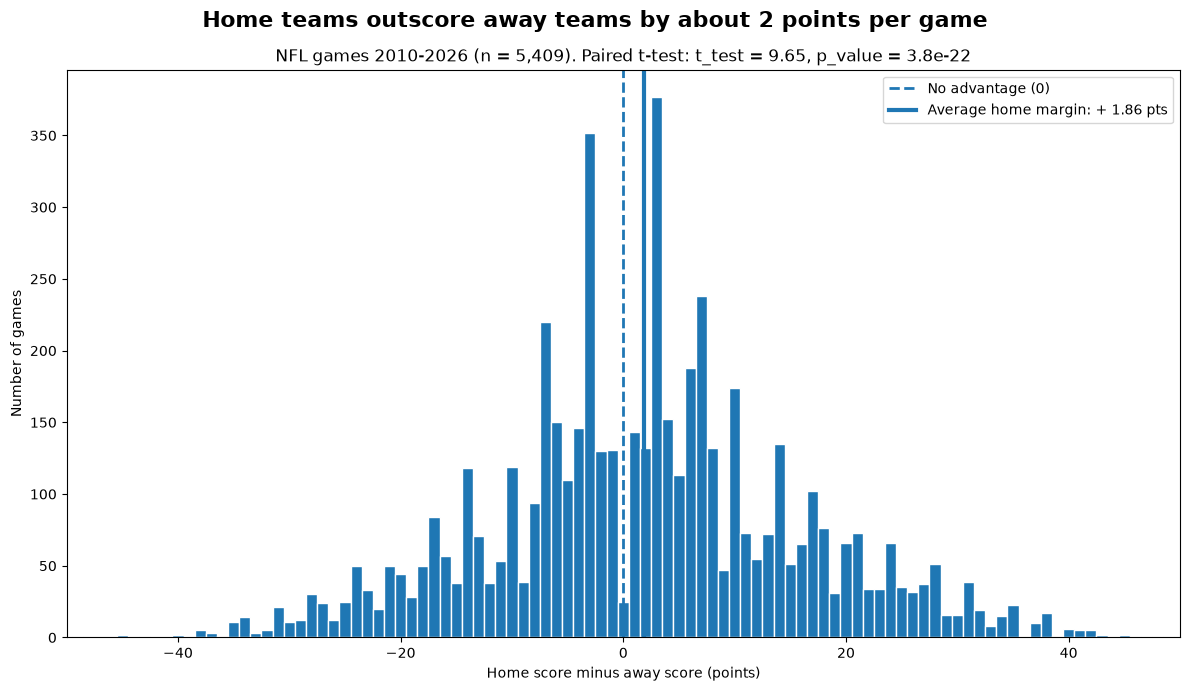

In [56]:
mean_margin = scores['Margin'].mean()
fig, ax = plt.subplots(figsize = (12, 7))
ax.hist(scores['Margin'], bins = np.arange(-50.5, 51.5, 1), edgecolor = 'white')


ax.axvline(0, linestyle = '--', linewidth = 2, label = 'No advantage (0)')
ax.axvline(mean_margin, linewidth=3, label=f'Average home margin: + {mean_margin:.2f} pts')
ax.legend()

ax.set_xlim(-50, 50)
ax.set_xlabel('Home score minus away score (points)')
ax.set_ylabel('Number of games')
fig.suptitle('Home teams outscore away teams by about 2 points per game', fontsize = 16, weight ='bold')
ax.set_title(f'NFL games 2010-2026 (n = {len(scores):,}). Paired t-test: t_test = {t_stat:.2f}, p_value = {p_value:.1e}', fontsize = 12)
plt.tight_layout()
plt.show()

### Conclusion
- Out of the 5,409 games, the home teams won 55% of them.
- Mean Margin = 1.86, Median = 2.0. So on average, home team outscored away team by 2 points.
- STD = 14.2 points which means the individual games vary a lot.
- P-Value = 3.8 x 10^-22, which is far below 0.05, so we reject the null hypothesis.

Home teams score significantly more points than away teams. A paired t-test is useful here because each match has a matched pair of scores (home and away). Although the test is statistically significant, it is relatively small when compared to the variation (std approximately 14 points). 

## Hypothesis Test #2 : Scoring trends by the seasons (By: Sara Karnik)

Do games have different average total points scrored thorugh different seasons?

- H0 (Null Hypothesis): There is no difference in the average total points scored per game across seasons
- H1 (Alternative Hypothesis): At least one season has a different average total points scored per game
- Significance level: α = 0.05

In [57]:
scores['TotalPoints']=scores['HomeScore']+scores['AwayScore']
print("number of games: ", len(scores))
print("mean total points: ", scores['TotalPoints'].mean())
print("median total points: ", scores['TotalPoints'].median())
print("Std of total points: ", scores['TotalPoints'].std())

print("Average points per season:")

number of games:  5409
mean total points:  44.38195599926049
median total points:  44.0
Std of total points:  13.983195211335993
Average points per season:


In [58]:
from scipy.stats import f_oneway

scores['Season'].unique()

one=scores[scores['Season']==2021]
two=scores[scores['Season']==2022]
three=scores[scores['Season']==2023]

stat, val=f_oneway(
    one['HomeScore']+one['AwayScore'],
    two['HomeScore']+two['AwayScore'],
    three['HomeScore']+three['AwayScore'],
)

print('pval=', val)
if val < 0.05:
    print("Reject the null hypothesis: average total points are different across seasons")
else:
    print("Fail to reject the null hypothesis.")

pval= 0.29826681345779915
Fail to reject the null hypothesis.


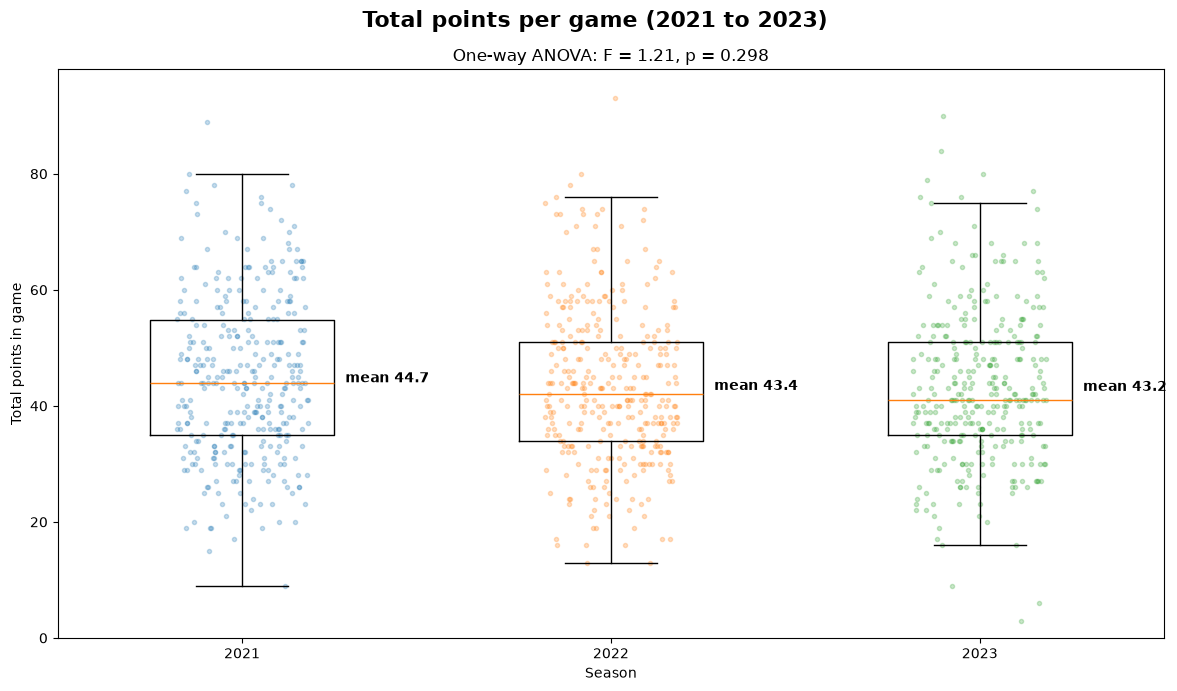

In [59]:
anova_seasons = [2021, 2022, 2023]
sub = scores[scores['Season'].isin(anova_seasons)]
groups = [sub.loc[sub['Season'] == s, 'TotalPoints'] for s in anova_seasons]

fig, ax = plt.subplots(figsize=(12, 7))

ax.boxplot(groups, positions=[0, 1, 2], widths = 0.5, showfliers = False)

for i, g in enumerate(groups):
    jitter = np.random.uniform(-0.18, 0.18, len(g))
    ax.scatter(i + jitter, g, alpha = 0.25, s = 9)
    ax.text(i + 0.28, g.mean(), f'mean {g.mean():.1f}', va = 'center', weight = 'bold')

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(anova_seasons)
ax.set_ylim(0, sub['TotalPoints'].max() + 5)
ax.set_xlabel('Season')
ax.set_ylabel('Total points in game')
fig.suptitle('Total points per game (2021 to 2023)', fontsize = 16, weight = 'bold')
ax.set_title(f'One-way ANOVA: F = {stat:.2f}, p = {val:.3f}', fontsize = 12)
plt.tight_layout()
plt.show()

### Conclusion
- Out of the 5,409 games, the mean total points scored per game was 44.38 with a median of 44 points
- The standard deviation was 13.98 points which shows that the total scores can vary between games
- We used a one way anova test to compare the average total points scores per game for three seasons(2021,2022,2023)
- P-Value = 0.2983 which is biger than 0.05 so we fail to reject the null hypothesis

From our results there isn't enough evidance to say that the average total points scored per game changed significantly from the 2021,2022 and 2023 seasons. Even through there is variation in scoring the differences in average total points are not staticially significant across three seaons. ANOVA is useful because we are checking to see how the mean of three independent gorups are comparing.

## Hypothesis Test #3 : Total Points vs. Point Difference (By: Ivan Valenzuela)

Is there a relationship between the total points scored in an NFL game and the difference in points between the winning and losing teams?

- H0 (Null Hypothesis): There is no linear correlation between the total points scored and the absolute point difference.
- H1 (Alternative Hypothesis): There is a linear correlation between the total points scored and the absolute point difference.
- Significance level: α = 0.05

In [60]:
scores['AbsoluteMargin'] = abs(scores['HomeScore'] - scores['AwayScore'])

print("Number of Games:", len(scores))
print("Mean Absolute Margin:", scores['AbsoluteMargin'].mean())
print("Median Absolute Margin:", scores['AbsoluteMargin'].median())
print("STD of Absolute Margin:", scores['AbsoluteMargin'].std())

Number of Games: 5409
Mean Absolute Margin: 11.148086522462563
Median Absolute Margin: 8.0
STD of Absolute Margin: 8.998277928356316


In [61]:
from scipy.stats import pearsonr

r, p_values = pearsonr(scores['TotalPoints'], scores['AbsoluteMargin'])
print("Pearson Correlation Coefficient:", r)
print("P-Value:", p_value)
if p_value < 0.05:
    print("Reject null hypothesis meaning there is a significant correlation between total points and point difference")
else:
    print("Fail to reject the null hypothesis")

Pearson Correlation Coefficient: 0.06721344850441453
P-Value: 3.821529434136647e-22
Reject null hypothesis meaning there is a significant correlation between total points and point difference


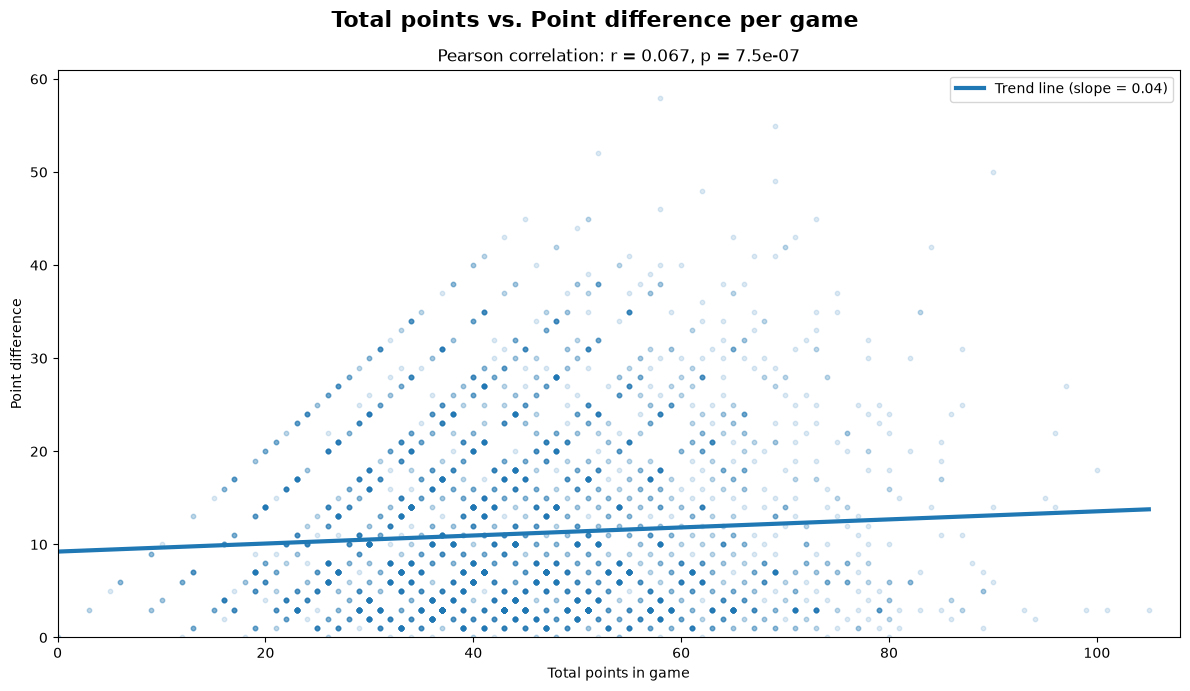

In [62]:
r3, p3 = stats.pearsonr(scores['TotalPoints'], scores['AbsoluteMargin'])
slope, intercept = np.polyfit(scores['TotalPoints'], scores['AbsoluteMargin'], 1)

fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(scores['TotalPoints'], scores['AbsoluteMargin'], s = 10, alpha = 0.15)

x = np.linspace(0, scores['TotalPoints'].max(), 100)
ax.plot(x, slope * x + intercept, linewidth = 3, label = f'Trend line (slope = {slope:.2f})')
ax.legend()

ax.set_xlim(0, scores['TotalPoints'].max() + 3)
ax.set_ylim(0, scores['AbsoluteMargin'].max() + 3)
ax.set_xlabel('Total points in game')
ax.set_ylabel('Point difference')
fig.suptitle('Total points vs. Point difference per game', fontsize = 16, weight = 'bold')
ax.set_title(f'Pearson correlation: r = {r3:.3f}, p = {p3:.1e}', fontsize = 12)
plt.tight_layout()
plt.show()

### Conclusion

- Out of 5,409 games, the Pearson Correlation Coefficient was approx. 0.0672.
- The correlation coefficient is positve but very close to zero, meaning there is a very weak relationship between the total points scored and the point difference.
- The p-value was approx. 7.51 & 10^-7, which is less than 0.05, so we reject the null hypothesis

So based on our results, there is a statistically significant relationship between the total points scored in NFL games and the difference in points between the winning and losing teams. However, since the correlation coefficient is very close to zero, the relationship is extremely weak. This suggests that even though games with more points tend to have slightly larger points differences, it doesnt't necessarily mean that higher-scoring games are less competitive. Overall, our results show that total points scored doesn't have a strong linear relationship with how close an NFL game is